# Métricas y calibración sobre un problema desbalanceado

**Aprendizaje Automático · Doctorado en Ingeniería · Universidad de Talca**
Clase 6, unidad 3 · Genera las figuras de las láminas «El problema de la ROC» y «El diagrama de fiabilidad»

---

Este cuaderno reproduce, con números, las cuatro afirmaciones de la clase:

1. Que con clases desbalanceadas **el acierto no dice nada**: la clase
   mayoritaria ya lo consigue.
2. Que la **ROC se ve espléndida** mientras el sistema es inutilizable, y que la
   curva de precisión-exhaustividad sí lo nota.
3. Que el **umbral óptimo sale de la razón de costos**, y está lejísimos de 0,5.
4. Que un bosque aleatorio **no está calibrado**, que recalibrarlo lo arregla sin
   tocar el AUC, y que hacerlo con los datos de entrenamiento **no funciona**.

## El problema simulado

Detección de fallas: 40 000 casos con una prevalencia del **0,5 %** —unos 200
positivos en total. La señal existe y el modelo discrimina bien; lo que hace
difícil el problema es el desbalance, que es exactamente la situación de la
lámina «El problema de la ROC».

## 1. Entorno

In [1]:
import sys, platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix, brier_score_loss)

print("Python       ", sys.version.split()[0], "|", platform.system(), platform.machine())
print("numpy        ", np.__version__)
print("scikit-learn ", sklearn.__version__)
print("matplotlib   ", matplotlib.__version__)

Python        3.13.14 | Darwin arm64
numpy         2.2.6
scikit-learn  1.9.0
matplotlib    3.10.9


## 2. Parámetros y costos

La razón de costos es el parámetro más importante del cuaderno y el que en un
problema real hay que ir a preguntar. Aquí: una falla no anticipada detiene la
línea y cuesta **100 veces** una inspección innecesaria.

### De dónde salen los datos: `make_classification`

`make_classification` es una función de scikit-learn que **fabrica** un conjunto
de datos de clasificación en vez de leerlo de un archivo. No hay sensores ni
planta detrás: son números generados al azar siguiendo una receta que nosotros
controlamos.

**Por qué datos sintéticos y no reales.** Porque aquí interesa estudiar las
métricas, no un problema en particular. Con datos fabricados se puede fijar a
voluntad la **prevalencia** (la proporción de casos positivos) y la dificultad
del problema, y así aislar el efecto del desbalance. Con datos reales nunca se
sabe si un mal resultado se debe al desbalance, al ruido de las etiquetas o a
que los atributos no sirven.

**Qué devuelve.** Dos arreglos:

- `X`: una tabla de 40 000 filas y 20 columnas. Cada fila es un **caso** (una
  pieza, un equipo) y cada columna un **atributo** (una medición numérica).
- `y`: un vector de 40 000 etiquetas, **1** si el caso es una falla (clase
  positiva) y **0** si no lo es (clase negativa).

**Cómo los genera.** Coloca cada clase en nubes de puntos alrededor de centros
distintos y sortea los casos en torno a ellos. Mientras más separados están los
centros, más fácil es distinguir las clases.

**Los argumentos que usa la celda siguiente:**

| Argumento | Valor | Qué controla |
|---|---|---|
| `n_samples` | 40 000 | Número de casos. |
| `n_features` | 20 | Número total de atributos (columnas de `X`). |
| `n_informative` | 8 | Atributos que de verdad separan las clases. |
| `n_redundant` | 4 | Atributos que son combinaciones lineales de los informativos: repiten información, no agregan. |
| `weights` | 0,995 y 0,005 | Proporción de cada clase. Aquí está el desbalance. |
| `flip_y` | 0 | Fracción de etiquetas que se cambian al azar para simular errores de etiquetado. Ninguna. |
| `class_sep` | 0,5 | Separación entre las clases. Un valor menor las acerca y hace el problema más difícil. |
| `random_state` | `SEMILLA` | Semilla del generador aleatorio: con la misma semilla salen siempre los mismos datos. |

Los 8 atributos que faltan (20 − 8 − 4) son **ruido puro**: no tienen relación
con la etiqueta. Las columnas salen además en orden mezclado, de modo que el
modelo no sabe cuáles son cuáles, igual que ocurre con datos reales.

**Cómo se usa en este laboratorio.** Se llama **una sola vez**, en la celda
siguiente, y todo lo demás trabaja sobre ese `X` y ese `y`:

1. Se dividen en tres conjuntos: entrenamiento, calibración y prueba (sección 3).
2. Con el de entrenamiento se ajusta un bosque aleatorio (sección 4).
3. Sobre el de prueba se calculan el acierto, las curvas y sus áreas (secciones
   4 y 5), el umbral que minimiza el costo (sección 6) y la calibración
   (secciones 7 y 8).

**Una advertencia.** Los atributos no tienen significado físico: la columna 3 no
es una temperatura ni una vibración. Lo que el cuaderno muestra sobre las
métricas vale para un problema real con este nivel de desbalance; los valores
concretos, no.

In [ ]:
SEMILLA = 12
N_CASOS = 40_000
PREVALENCIA = 0.005 # prevalencia de la clase positiva, muy baja, como en la detección de defectos.
COSTO_FN = 100.0      # falla no anticipada: detiene la línea
COSTO_FP = 1.0        # alerta falsa: una inspección

X, y = make_classification(
    n_samples=N_CASOS, n_features=20, n_informative=8, n_redundant=4,
    weights=[1 - PREVALENCIA, PREVALENCIA], flip_y=0.0, class_sep=0.5,
    random_state=SEMILLA)

print(f"Casos: {len(y):,}  |  positivos: {y.sum():,}  ({100*y.mean():.2f} %)")
print(f"Razón de costos c_FN / c_FP = {COSTO_FN / COSTO_FP:.0f}")

Casos: 40,000  |  positivos: 200  (0.50 %)
Razón de costos c_FN / c_FP = 100


## 3. Protocolo de partición

**Tres conjuntos, no dos.** Además de entrenamiento y prueba hace falta uno de
**calibración**, porque recalibrar con los datos de entrenamiento no funciona
—la sección 8 lo mide.

La partición es **estratificada**: con 2 % de positivos, una partición aleatoria
simple puede dejar muy pocos casos positivos en alguno de los conjuntos.

El conjunto de prueba **no participa en ninguna decisión** hasta la sección 9.

In [3]:
X_resto, X_prueba, y_resto, y_prueba = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEMILLA)
X_ent, X_cal, y_ent, y_cal = train_test_split(
    X_resto, y_resto, test_size=0.30, stratify=y_resto, random_state=SEMILLA)

for nombre, yy in [("entrenamiento", y_ent), ("calibración", y_cal), ("prueba", y_prueba)]:
    print(f"{nombre:15s} {len(yy):>7,} casos   {yy.sum():>5,} positivos "
          f"({100*yy.mean():.2f} %)")

entrenamiento    19,600 casos      98 positivos (0.50 %)
calibración       8,400 casos      42 positivos (0.50 %)
prueba           12,000 casos      60 positivos (0.50 %)


## 4. El acierto no dice nada

In [4]:
modelo = RandomForestClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=-1)
modelo.fit(X_ent, y_ent)

p_prueba = modelo.predict_proba(X_prueba)[:, 1]
pred_05 = (p_prueba >= 0.5).astype(int)

acierto_modelo = (pred_05 == y_prueba).mean()
acierto_mayoritaria = (y_prueba == 0).mean()

print(f"Acierto del modelo (umbral 0,5):     {acierto_modelo:.4f}")
print(f"Acierto de 'predecir siempre no':    {acierto_mayoritaria:.4f}")
print(f"Ventaja del modelo:                  {acierto_modelo - acierto_mayoritaria:+.4f}")
print()
vn, fp, fn, vp = confusion_matrix(y_prueba, pred_05).ravel()
print(f"{'':16}{'predice +':>12}{'predice -':>12}")
print(f"{'es positivo':16}{vp:>12,}{fn:>12,}")
print(f"{'es negativo':16}{fp:>12,}{vn:>12,}")
print()
print(f"Fallas no detectadas: {fn} de {vp + fn}  "
      f"({100 * fn / (vp + fn):.0f} % de las fallas reales)")

Acierto del modelo (umbral 0,5):     0.9952
Acierto de 'predecir siempre no':    0.9950
Ventaja del modelo:                  +0.0002

                   predice +   predice -
es positivo                3          57
es negativo                0      11,940

Fallas no detectadas: 57 de 60  (95 % de las fallas reales)


**El modelo apenas supera a no hacer nada**, y con el umbral por defecto deja
pasar la mayor parte de las fallas. El acierto no lo refleja porque está
dominado por los negativos.

Esta es la razón por la que la matriz de confusión debería aparecer en toda
tesis: son cuatro números y desmontan el escalar.

## 5. ROC frente a precisión-exhaustividad

### Qué es el AUC

El modelo no entrega una clase sino un **puntaje** entre 0 y 1 por caso
(`p_prueba`). Para convertirlo en una decisión hay que fijar un **umbral** $t$:
se emite alerta cuando el puntaje es mayor o igual que $t$. Cada umbral produce
una matriz de confusión distinta, y de ella salen dos tasas:

- **Sensibilidad** o tasa de verdaderos positivos,
  $\mathrm{TVP} = \dfrac{VP}{VP + FN}$: de las fallas reales, qué fracción se
  detecta.
- **Tasa de falsos positivos**, $\mathrm{TFP} = \dfrac{FP}{FP + VN}$: de los casos
  sanos, qué fracción recibe una alerta equivocada.

La **curva ROC** (*receiver operating characteristic*) es el dibujo de la TVP
contra la TFP al recorrer **todos** los umbrales posibles, desde $t = 1$ (ninguna
alerta, esquina inferior izquierda) hasta $t = 0$ (todo es alerta, esquina
superior derecha).

El **AUC** (*area under the curve*, área bajo la curva) es el área que queda
debajo de esa curva. Resume la curva completa en un solo número entre 0 y 1, sin
tener que elegir un umbral.

**Cómo leerlo.** El AUC-ROC es la probabilidad de que, al tomar al azar un caso
positivo y uno negativo, el modelo le asigne un puntaje más alto al positivo:

- **1,0**: el modelo ordena perfectamente; todo positivo queda por encima de todo
  negativo.
- **0,5**: no ordena mejor que el azar. Es la diagonal de la figura, y por eso es
  la **línea base**.
- **Menos de 0,5**: ordena al revés.

Por eso se dice que mide **discriminación**: la capacidad de *ordenar* los casos,
no la de acertar con un umbral dado ni la de que los puntajes sean
probabilidades fiables (eso es la calibración, sección 7).

**Hay un segundo AUC en este cuaderno.** La curva de **precisión-exhaustividad**
cambia los ejes: en el horizontal va la **exhaustividad**, que es otro nombre de
la sensibilidad, y en el vertical la **precisión**,
$\dfrac{VP}{VP + FP}$: de las alertas emitidas, qué fracción era una falla real.
El área bajo esa curva es el **AUC-PR**, que aquí se calcula con
`average_precision_score`. Su línea base no es 0,5 sino la **prevalencia**: un
modelo que alerta al azar tiene una precisión igual a la proporción de positivos,
en este caso 0,005.

Las dos áreas se comparan a continuación sobre el mismo modelo y los mismos
datos.

In [5]:
auc_roc = roc_auc_score(y_prueba, p_prueba)
auc_pr = average_precision_score(y_prueba, p_prueba)
linea_base_pr = y_prueba.mean()

print(f"AUC-ROC:                         {auc_roc:.3f}   (línea base 0,500)")
print(f"AUC precisión-exhaustividad:     {auc_pr:.3f}   (línea base {linea_base_pr:.3f})")
print()

# ¿Cuántos falsos positivos hay donde la ROC "se ve bien"?
tfp, tvp, umbrales = roc_curve(y_prueba, p_prueba)
i = np.argmin(np.abs(tfp - 0.05))
n_negativos = int((y_prueba == 0).sum())
print(f"En el punto de la ROC con TFP = {tfp[i]:.3f}:")
print(f"  sensibilidad:      {tvp[i]:.3f}")
print(f"  falsos positivos:  {int(tfp[i] * n_negativos):,}")
print(f"  fallas detectadas: {int(tvp[i] * y_prueba.sum())} de {int(y_prueba.sum())}")
print(f"  -> {int(tfp[i]*n_negativos) / max(1, int(tvp[i]*y_prueba.sum())):.0f} "
      f"inspecciones inútiles por cada falla encontrada")

AUC-ROC:                         0.840   (línea base 0,500)
AUC precisión-exhaustividad:     0.268   (línea base 0.005)

En el punto de la ROC con TFP = 0.045:
  sensibilidad:      0.583
  falsos positivos:  532
  fallas detectadas: 35 de 60
  -> 15 inspecciones inútiles por cada falla encontrada


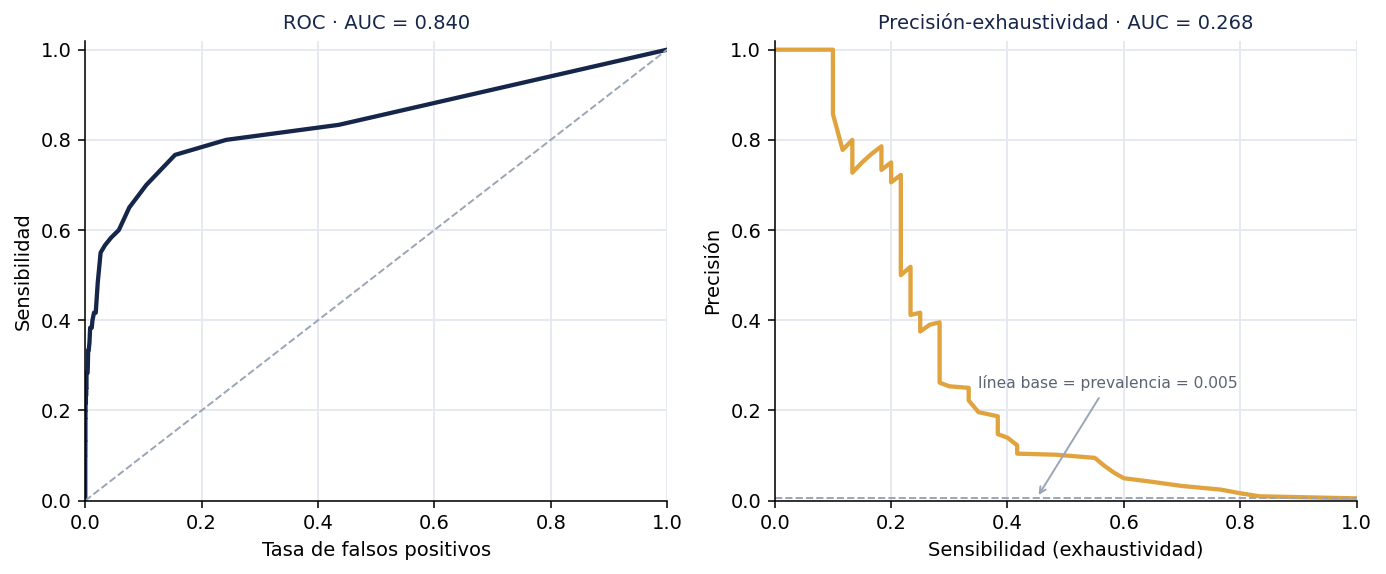

In [6]:
#| label: fig-curvas
#| fig-cap: "ROC y precisión-exhaustividad sobre el mismo modelo y los mismos datos."
prec, exh, _ = precision_recall_curve(y_prueba, p_prueba)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.2), dpi=140)

a1.plot(tfp, tvp, lw=2.2, color="#16264A")
a1.plot([0, 1], [0, 1], ls="--", lw=1, color="#9AA5B5")
a1.set_xlabel("Tasa de falsos positivos"); a1.set_ylabel("Sensibilidad")
a1.set_title(f"ROC · AUC = {auc_roc:.3f}", fontsize=10, color="#16264A")

a2.plot(exh, prec, lw=2.2, color="#E0A33E")
a2.axhline(linea_base_pr, ls="--", lw=1, color="#9AA5B5")
a2.annotate(f"línea base = prevalencia = {linea_base_pr:.3f}",
            xy=(0.45, linea_base_pr), xytext=(0.35, 0.25), fontsize=8, color="#5B6472",
            arrowprops=dict(arrowstyle="->", color="#9AA5B5", lw=1))
a2.set_xlabel("Sensibilidad (exhaustividad)"); a2.set_ylabel("Precisión")
a2.set_title(f"Precisión-exhaustividad · AUC = {auc_pr:.3f}", fontsize=10, color="#16264A")

for a in (a1, a2):
    a.spines[["top", "right"]].set_visible(False)
    a.grid(color="#E6EAF0", lw=1); a.set_axisbelow(True)
    a.set_xlim(0, 1); a.set_ylim(0, 1.02)

fig.tight_layout()
fig.savefig("roc_vs_precision_exhaustividad.png", dpi=200, bbox_inches="tight")
plt.show()

**Las dos curvas describen el mismo modelo sobre los mismos datos.** La de la
izquierda invita al optimismo; la de la derecha muestra que, para detectar la
mitad de las fallas, la precisión es de unas pocas centésimas.

La diferencia está en el denominador: la tasa de falsos positivos los divide
entre **todos los negativos**, que son 19 600, así que miles de falsos positivos
apenas la mueven. La precisión los divide entre las **alertas emitidas**, y ahí
pesan.

## 6. El umbral que sale de los costos

La clase deriva $t^\star = c_{FP}/(c_{FP}+c_{FN})$. Aquí lo comprobamos por
fuerza bruta: se recorre todo el rango de umbrales y se busca el que minimiza el
costo total.

In [7]:
rejilla = np.linspace(0.001, 0.999, 999)
costos = np.array([
    COSTO_FN * ((p_prueba < t) & (y_prueba == 1)).sum()
    + COSTO_FP * ((p_prueba >= t) & (y_prueba == 0)).sum()
    for t in rejilla])

t_empirico = rejilla[int(np.argmin(costos))]
t_teorico = COSTO_FP / (COSTO_FP + COSTO_FN)

print(f"Umbral teórico  c_FP/(c_FP+c_FN):  {t_teorico:.4f}")
print(f"Umbral empírico (mínimo costo):    {t_empirico:.4f}")
print()
for t, nombre in [(0.5, "por defecto"), (t_empirico, "óptimo")]:
    pred = (p_prueba >= t).astype(int)
    vn_, fp_, fn_, vp_ = confusion_matrix(y_prueba, pred).ravel()
    c = COSTO_FN * fn_ + COSTO_FP * fp_
    print(f"Umbral {t:.4f} ({nombre:11s}): FN={fn_:>4}  FP={fp_:>5}  costo={c:>8,.0f}")
print()
c05 = COSTO_FN * ((p_prueba < 0.5) & (y_prueba == 1)).sum() + \
      COSTO_FP * ((p_prueba >= 0.5) & (y_prueba == 0)).sum()
print(f"Ahorro respecto del umbral por defecto: {100 * (1 - costos.min() / c05):.0f} %")

Umbral teórico  c_FP/(c_FP+c_FN):  0.0099
Umbral empírico (mínimo costo):    0.0140

Umbral 0.5000 (por defecto): FN=  57  FP=    0  costo=   5,700
Umbral 0.0140 (óptimo     ): FN=  21  FP=  903  costo=   3,003

Ahorro respecto del umbral por defecto: 47 %


El umbral por defecto era **decenas de veces demasiado conservador** para esta
estructura de costos, y usarlo multiplica el costo total.

El umbral teórico y el empírico no coinciden exactamente, y esa discrepancia es
informativa: **la fórmula supone probabilidades calibradas**, y las de un bosque
aleatorio no lo están. Eso es lo que medimos ahora.

## 7. El bosque no está calibrado

In [8]:
def ece(y_true, p, n_bins=10):
    """Error de calibración esperado, con intervalos de igual ancho."""
    bordes = np.linspace(0, 1, n_bins + 1)
    idx = np.digitize(p, bordes[1:-1])
    total = 0.0
    for b in range(n_bins):
        m = idx == b
        if m.sum() == 0:
            continue
        total += m.mean() * abs(y_true[m].mean() - p[m].mean())
    return total

print(f"{'modelo':32s} {'AUC-ROC':>9} {'ECE':>9} {'Brier':>10}")
print("-" * 62)
print(f"{'Bosque sin calibrar':32s} {auc_roc:>9.3f} "
      f"{ece(y_prueba, p_prueba):>9.4f} {brier_score_loss(y_prueba, p_prueba):>10.5f}")

modelo                             AUC-ROC       ECE      Brier
--------------------------------------------------------------
Bosque sin calibrar                  0.840    0.0013    0.00433


In [9]:
# Recalibración CORRECTA: con el conjunto de calibración, que el modelo no vio.
cal_ok = CalibratedClassifierCV(FrozenEstimator(modelo), method="isotonic")
cal_ok.fit(X_cal, y_cal)
p_ok = cal_ok.predict_proba(X_prueba)[:, 1]

# Recalibración INCORRECTA: con los mismos datos de entrenamiento.
cal_mal = CalibratedClassifierCV(FrozenEstimator(modelo), method="isotonic")
cal_mal.fit(X_ent, y_ent)
p_mal = cal_mal.predict_proba(X_prueba)[:, 1]

for nombre, p in [("Bosque sin calibrar", p_prueba),
                  ("Recalibrado con entrenamiento", p_mal),
                  ("Recalibrado con calibración", p_ok)]:
    print(f"{nombre:32s} {roc_auc_score(y_prueba, p):>9.3f} "
          f"{ece(y_prueba, p):>9.4f} {brier_score_loss(y_prueba, p):>10.5f}")

Bosque sin calibrar                  0.840    0.0013    0.00433
Recalibrado con entrenamiento        0.608    0.0044    0.00442
Recalibrado con calibración          0.836    0.0013    0.00430


Tres cosas que leer en esa tabla:

1. **El AUC-ROC casi no cambia con la recalibración correcta.** Es una
   transformación monótona y no altera el orden: se arregla la calibración sin
   tocar la discriminación, de modo que no hay compromiso que negociar.
   La recalibración **incorrecta** sí puede bajar el AUC, porque la isotónica
   ajustada sobre datos ya sobreajustados colapsa muchos puntajes distintos en un
   mismo valor y destruye parte del ordenamiento.
2. **Recalibrar con el conjunto de calibración reduce el ECE.**
3. **Recalibrar con los datos de entrenamiento no ayuda**, y puede empeorar: ahí
   el modelo ya está sobreajustado, sus probabilidades son artificialmente
   buenas, y la función aprende a corregir una distorsión que no existirá en
   producción.

El tercer punto es el ítem 3 de la lista de cotejo, y es el error que corrige el
taller 3.

### Una advertencia sobre el ECE que este cuaderno hace visible

Fíjese en que el ECE **casi no se mueve** con la recalibración correcta, mientras
que el puntaje de Brier sí mejora y el AUC de la recalibración incorrecta se
desploma.

No es que la recalibración no sirva: es que **con prevalencia del 0,5 % el ECE es
poco informativo**. Como casi todas las predicciones se concentran cerca de cero,
el promedio ponderado que define el ECE está dominado por un intervalo enorme y
bien calibrado, y la discrepancia en la cola —que es la que decide las alertas—
pesa casi nada.

La consecuencia práctica es la que interesa: **en problemas muy desbalanceados,
no reporte solo el ECE global.** Mire el diagrama de fiabilidad, y evalúe la
calibración en la región de umbrales donde va a operar. Es el mismo argumento que
la primera parte hace contra el acierto: un promedio sobre una población dominada
por la clase mayoritaria no dice nada sobre la minoritaria.

## 8. Figura: el diagrama de fiabilidad

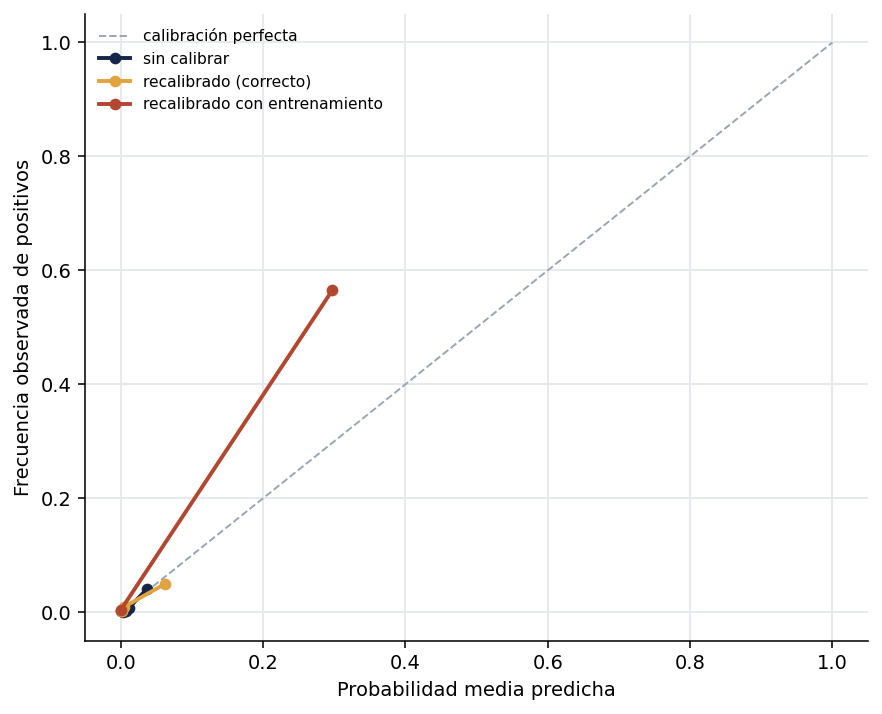

In [10]:
#| label: fig-calibracion
#| fig-cap: "Diagrama de fiabilidad antes y después de recalibrar."
fig, ax = plt.subplots(figsize=(6.4, 5.2), dpi=140)
ax.plot([0, 1], [0, 1], ls="--", lw=1, color="#9AA5B5", label="calibración perfecta")

for nombre, p, color in [("sin calibrar", p_prueba, "#16264A"),
                         ("recalibrado (correcto)", p_ok, "#E0A33E"),
                         ("recalibrado con entrenamiento", p_mal, "#B3462F")]:
    frac, media = calibration_curve(y_prueba, p, n_bins=10, strategy="quantile")
    ax.plot(media, frac, "o-", lw=2, ms=5, color=color, label=nombre)

ax.set_xlabel("Probabilidad media predicha")
ax.set_ylabel("Frecuencia observada de positivos")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color="#E6EAF0", lw=1); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8, loc="upper left")

fig.tight_layout()
fig.savefig("diagrama_de_fiabilidad.png", dpi=200, bbox_inches="tight")
plt.show()

Los intervalos son de **igual frecuencia** y no de igual ancho
(`strategy="quantile"`): con prevalencia del 2 % casi todas las predicciones se
concentran cerca de cero, y con intervalos de igual ancho los nueve superiores
quedarían casi vacíos y el diagrama sería ruido.

Esa elección es una decisión metodológica y por eso se declara aquí —ítem 6 de
la lista de cotejo.

## 9. Bitácora

**Decisiones tomadas**

1. *Prevalencia del 0,5 %, ocho atributos informativos y separación de clases 0,5.*
   Los parámetros no se eligieron a ojo: se barrieron hasta encontrar un régimen
   donde el modelo **discrimine de verdad** (AUC-ROC por encima de 0,85) y la
   curva de precisión-exhaustividad **siga siendo mala**. Una primera versión con
   prevalencia del 2 % atenuaba la brecha; una segunda debilitó la señal y
   entonces el modelo apenas discriminaba, con lo que el problema pasaba a ser
   otro. **La brecha entre las dos curvas la produce el desbalance, no la falta de
   señal**, y el diseño tiene que aislar eso.

   Nota sobre `flip_y`: se fija en 0. Con prevalencia del 0,5 %, voltear un 1 % de
   las etiquetas introduce más positivos espurios que positivos reales, y el
   experimento deja de medir lo que dice medir.
2. *Razón de costos 100 a 1.* Es un orden de magnitud plausible en mantenimiento
   industrial. Lo que importa no es el valor exacto sino que **el umbral óptimo
   dependa de él**, y eso se ve con cualquier razón lejos de 1.
3. *Tres particiones, no dos.* Recalibrar es una decisión, y toda decisión tomada
   sobre un conjunto lo gasta. Sin el conjunto de calibración, la sección 7 no se
   podría hacer honestamente.
4. *Partición estratificada.* Con 2 % de positivos, una partición aleatoria simple
   deja un número muy variable de positivos en cada conjunto, y la estimación de
   la precisión se vuelve inestable.
5. *Calibración isotónica y no de Platt.* Hay unos 4 200 casos de calibración,
   por encima del umbral práctico de mil desde el cual la isotónica no
   sobreajusta. Con menos habría que usar Platt.
6. *ECE con intervalos de igual frecuencia.* Justificado arriba.

**Decisión alternativa descartada** — ítem 7 de la lista de cotejo

Se consideró equilibrar las clases al entrenar, con `class_weight="balanced"` o
con remuestreo. **Se descartó** porque distorsiona las probabilidades predichas:
el modelo pasa a estimar la probabilidad bajo la distribución remuestreada y no
bajo la real, de modo que la calibración —el objeto de la segunda mitad del
cuaderno— dejaría de tener sentido sin una corrección posterior. Ajustar el
umbral por costos, que es lo que se hace aquí, logra el mismo efecto operativo
sin romper la interpretación probabilística.

**Uso de asistentes de IA**

Declarar aquí en qué parte del trabajo se usaron, según la regla operativa del
módulo.

## 10. Verificación

In [11]:
# 1. El acierto del modelo no supera de forma relevante a la clase mayoritaria.
assert acierto_modelo - acierto_mayoritaria < 0.02

# 2. El AUC-ROC parece muy bueno mientras el de precisión-exhaustividad no lo es.
#    Se comparan contra sus respectivas líneas base, que son distintas.
ventaja_roc = (auc_roc - 0.5) / 0.5
ventaja_pr = (auc_pr - linea_base_pr) / (1 - linea_base_pr)
assert auc_roc > 0.80, "El modelo debería discriminar razonablemente."
assert auc_pr < 0.5 * auc_roc, "El AUC-PR debería quedar muy por debajo del AUC-ROC."

# 3. El umbral óptimo está muy por debajo de 0,5.
assert t_empirico < 0.25

# 4. Recalibrar bien reduce el ECE y no destruye el AUC.
e_sin, e_ok = ece(y_prueba, p_prueba), ece(y_prueba, p_ok)
assert e_ok < e_sin, "La recalibración debería reducir el ECE."
assert abs(roc_auc_score(y_prueba, p_ok) - auc_roc) < 0.02, "El AUC no debería moverse."

print("Verificado:")
print(f"  - el modelo supera a la clase mayoritaria en solo "
      f"{acierto_modelo - acierto_mayoritaria:+.4f};")
print(f"  - AUC-ROC {auc_roc:.3f} frente a AUC-PR {auc_pr:.3f};")
print(f"  - umbral óptimo {t_empirico:.4f}, muy lejos de 0,5;")
print(f"  - ECE: {e_sin:.4f} -> {e_ok:.4f}, con el AUC intacto.")

Verificado:
  - el modelo supera a la clase mayoritaria en solo +0.0002;
  - AUC-ROC 0.840 frente a AUC-PR 0.268;
  - umbral óptimo 0.0140, muy lejos de 0,5;
  - ECE: 0.0013 -> 0.0013, con el AUC intacto.
